# student exam performance 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [94]:
df = pd.read_csv("StudentsPerformance.csv") # read the csv file

In [96]:
df.shape     # number of rows and columns

(1000, 8)

In [97]:
df.head()    # first 5 rows

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [98]:
df.columns   # columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [99]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [100]:
df.isnull().sum()     # sum of null value 

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [101]:
df.duplicated().sum() #sum of duplicate value

np.int64(0)

In [102]:
df.describe()  # statisticl information

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [103]:
 # clean the dataset using pandas
df.dtypes # shows the datatype

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

In [ ]:
# clean the data 
df.columns = df.columns.str.strip() # clean the columns names
df.df.drop_duplicates()  # remove the duplicate rows

In [104]:
#verify the dataset
print("dataset shape(rows,columns): ",df.shape)
print("missing values: ",df.isnull().sum().sum()) # use 2 times sum due to it shows direct integer number
print("Duplicate rows: ",df.duplicated().sum())

dataset shape(rows,columns):  (1000, 8)
missing values:  0
Duplicate rows:  0


### Analze the marks using numpy

In [105]:
math = df["math score"].to_numpy()
reading = df["reading score"].to_numpy()
writing = df["writing score"].to_numpy()

print("Math average :",np.mean(math))
print("Readin average:",np.mean(reading))
print("Writing average:",np.mean(writing))


Math average : 66.089
Readin average: 69.169
Writing average: 68.054


### Create a bar chart of average marks

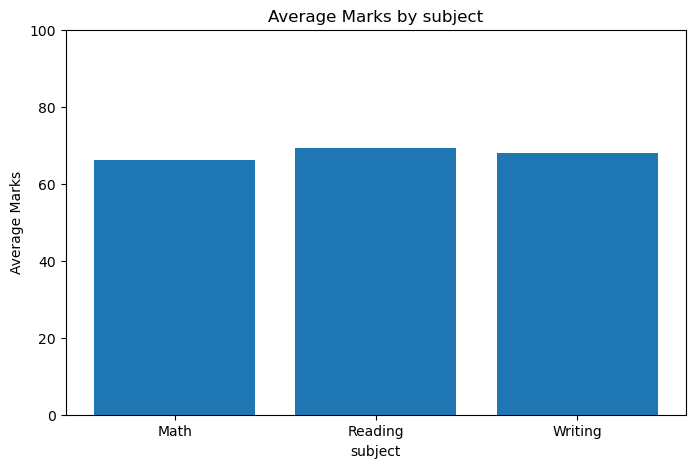

In [106]:
# Calculate average marks in each subject
subjects = ["Math", "Reading", "Writing"]

averages = [
    np.mean(df["math score"]),
    np.mean(df["reading score"]),
    np.mean(df["writing score"])
    ]

# creating bar chart 
plt.figure(figsize=(8,5))
plt.bar(subjects,averages)

plt.title("Average Marks by subject")
plt.xlabel("subject")
plt.ylabel("Average Marks")
plt.ylim(0,100)
plt.show()


### Mathematics score distribution

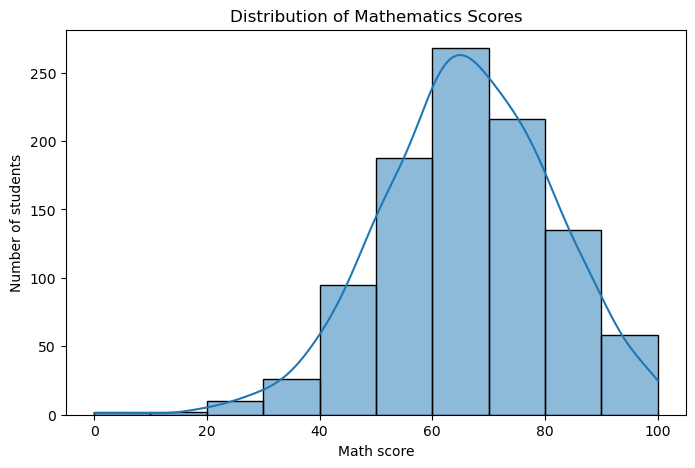

In [107]:
# create a histtogram
plt.figure(figsize=(8,5))

sns.histplot(data=df,x="math score",bins=10,kde=True)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Math score")
plt.ylabel("Number of students")

plt.show()

# Histogram bars: Show how many students fall into each range.
# KDE curve: Shows the approximate distribution pattern of scores.

### Create a correlation heatmap

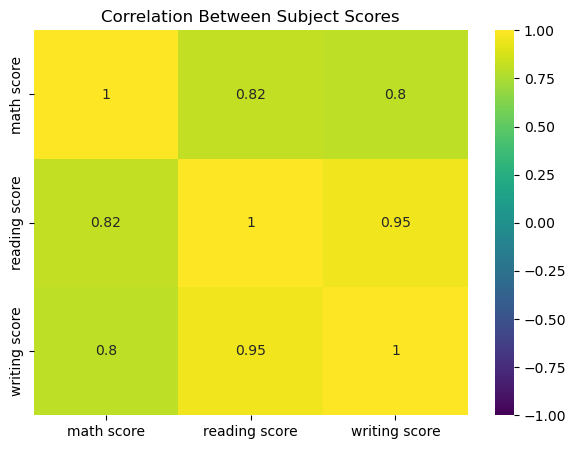

In [108]:
# select numerical columns
scores = df[["math score","reading score","writing score"]]

# calculation correlation 
correlation = scores.corr()

# plot heatmap
plt.figure(figsize=(7,5))

sns.heatmap(correlation,annot=True,cmap="viridis",vmin =-1,vmax=1)
plt.title("Correlation Between Subject Scores")
plt.show()

### Analyze test preparation and average marks

In [109]:
# Compare average marks by test preparation course
preparation_analysis = df.groupby(
    "test preparation course"
)[["math score", "reading score", "writing score"]].mean()

preparation_analysis

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


### Visualize the comparison

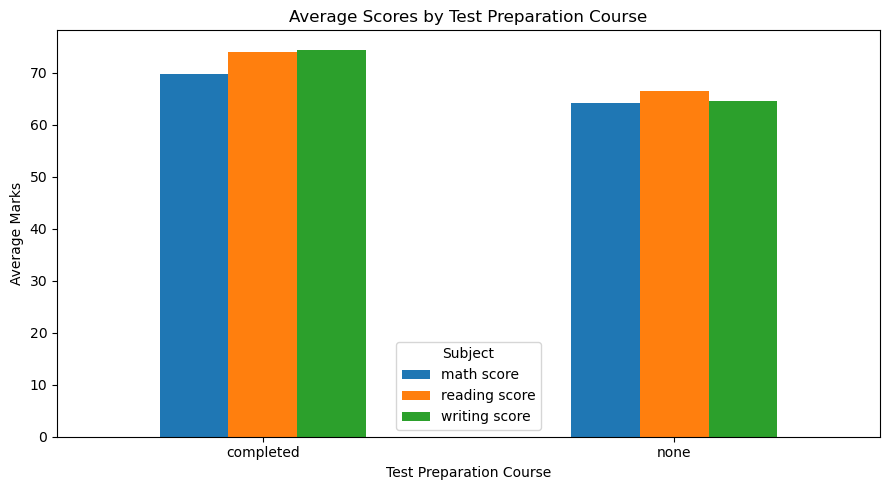

In [110]:
preparation_analysis.plot(
    kind="bar",
    figsize=(9,5)
)
plt.title("Average Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

### save the clean dataset

In [111]:
df.to_csv("cleaned_student_performance.csv",index=False)
print("Cleaned dataset saved successfully!!!")

Cleaned dataset saved successfully!!!
